In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import os
import sys

from configparser import ConfigParser
from pathlib import Path

# Set the working directory to the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src" / "insurance_pricing").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

# Make your source package importable
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from src.Insurance_pricing.data import Find_N_datasets, inspect_dataset

<function str.lower()>

In [ ]:
def monetary_bar_chart(data: object, currency:str = 'GBP'):
    """
    Generate a bar chart of claim costs by claims type.

    Parameters
    ----------
    data : pandas.DataFrame
        Dataset containing claims types and their associated costs.
    currency : str, default="GBP"
        Target currency code. Supported currencies are GBP, EUR,
        USD and JPY.

    Raises
    ------
    ValueError
        If the specified currency is not supported.

    Returns
    -------
    None
        Displays the resulting bar chart.
    """

    # Gets the EUR to the currency of choices exchange rate
    rate, currencies = exchange_currency(currency,give_currencies=True)

    df = data.copy()

    # Convert the entire column using Pandas
    df["Cost_claims_year"] = df["Cost_claims_year"] * rate

    symbol = currencies[currency]
    
    # Set the chart style
    sns.set_theme(style="whitegrid", context="notebook")

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.barplot(
        data=df,
        x="Claims_type",
        y="Cost_claims_year",
        color="#4878A8",
        errorbar=None,
        ax=ax
    )

    # Titles and labels
    ax.set_title(
        "Total Cost by Claims Type",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Claims Type", fontsize=11)
    ax.set_ylabel(f"Total Cost ({symbol})", fontsize=11)

    # Formats the y-axis as currency
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{symbol}{value:,.0f}")
    )

    # Rotates category labels for readability
    ax.tick_params(axis="x", labelrotation=35)
    plt.setp(ax.get_xticklabels(), ha="right")

    # Display the cost above each bar
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[
                f"{symbol}{bar.get_height():,.0f}"
                for bar in container
            ],
            padding=4,
            fontsize=9
        )

    # Clean up the layout
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.12)

    sns.despine()
    plt.tight_layout()
    plt.show()

def exchange_currency(to_currency:str, from_currency:str ='EUR', give_currencies:bool=False):

    from forex_python.converter import CurrencyRates

    currencies = {
        "GBP": "£",
        "EUR": "€",
        "USD": "$",
        "JPY": "¥"
    }
    
    if to_currency not in currencies or from_currency not in currencies:
        raise ValueError(
            f"Invalid currency: {to_currency if to_currency not in currencies else from_currency}. "
            f"Choose from {', '.join(currencies.keys())}."
        )

    # cost convertion
    c = CurrencyRates()

    # Gets the EUR to the currency of choices exchange rate
    return c.get_rate("EUR", to_currency) if give_currencies else c.get_rate("EUR", to_currency), currencies

In [3]:
# Looks at what the highest number of claims within the dataset seems to be given the raw "Claims.csv" file
paths = Find_N_datasets(2)
motor = pd.read_csv(paths[0], sep=";")
claims = pd.read_csv(paths[1], sep=";")

motor_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Raw\Motor.csv
claims_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Raw\Claims.csv


In [ ]:
inspect_dataset(claims) #inspection shows there's no null and/or missing elements in the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7366 entries, 0 to 7365
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   7366 non-null   int64  
 1   Cost_claims_year     7366 non-null   float64
 2   Cost_claims_by_type  7366 non-null   float64
 3   Claims_type          7366 non-null   object 
dtypes: float64(2), int64(1), object(1)
memory usage: 230.3+ KB

Info of the dataset:
None

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
    

Checking the missing values:
ID                     0
Cost_claims_year       0
Cost_claims_by_type    0
Claims_type            0
dtype: int64

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
   

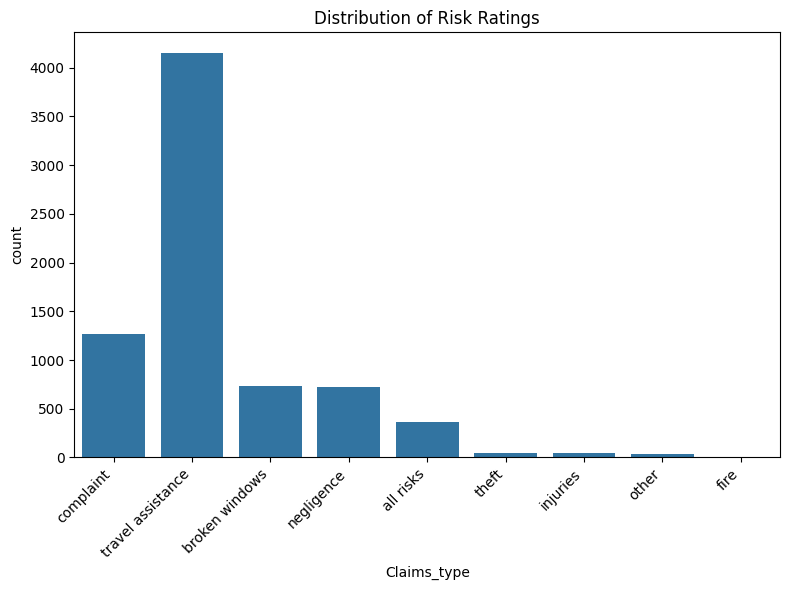

In [5]:

plt.figure(figsize=(8,6))
sns.countplot(x='Claims_type', data=claims)
plt.title('Distribution of Risk Ratings')
plt.xticks(rotation=45, ha="right")  # Rotate category names
plt.tight_layout()  # Stop labels being cut off
plt.show()

In [6]:
temp = claims.copy()
temp.drop_duplicates(subset='ID',inplace=True)
temp

,ID,Cost_claims_year,Cost_claims_by_type,Claims_type
0,28,332.02,332.02,complaint
1,36,57.35,57.35,travel assistance
2,42,57.50,57.50,travel assistance
3,60,138.90,67.25,travel assistance
5,77,1574.93,1574.93,complaint
...,...,...,...,...
7359,53413,298.87,49.95,travel assistance
7362,53419,497.47,497.47,complaint
7363,53441,73.32,73.32,travel assistance
7364,53442,46.89,46.89,travel assistance


In [7]:
# Adds each unique entry for the claims then groups it by claims type.
result = temp.groupby('Claims_type')['Cost_claims_year'].sum().reset_index()

# Sort from highest to lowest cost
result = result.sort_values(
    by="Cost_claims_year",
    ascending=True
)

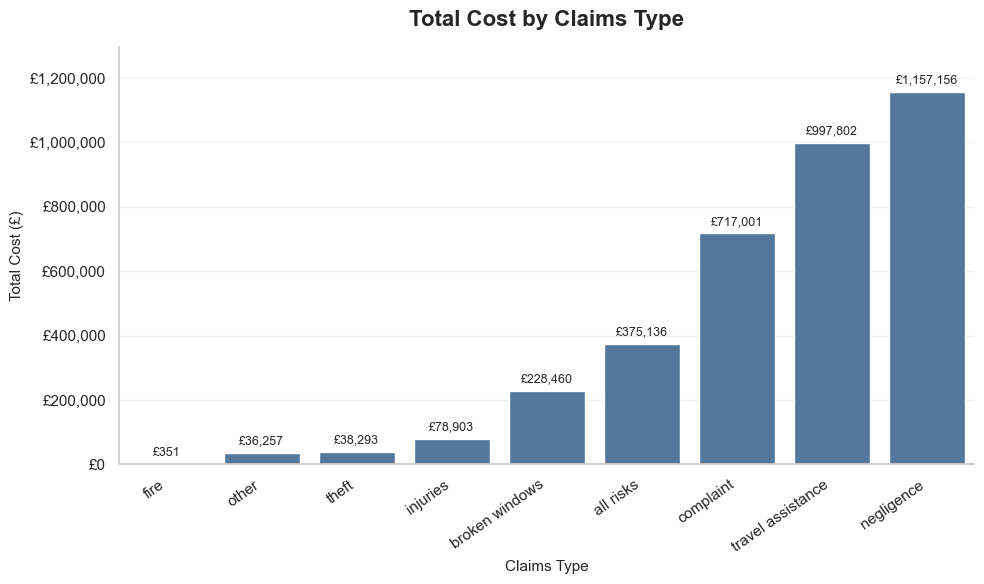

In [8]:
try:
    monetary_bar_chart(result.copy(), 'GBP')

except ValueError as error:
    print(error)